# Разработка модели поведенческого скоринга

## Подготовка рабочего пространства

* Дайте этой тетрадке Jupyter название, которое корректно отражает суть проекта.
* Опишите постановку задачи своими словами, коротко зафиксировав основной смысл.
* Опишите данные, которые даны для решения задачи.

Необходимо построить модель поведенческого скоринга, которая по данным о клиенте в выбранный месяц прогнозирует, возникнет ли у него просрочка на 90 дней или более.​

## Перевод бизнес-задачи на язык машинного обучения

* Напишите, что конкретно будете делать, пользуясь терминами машинного обучения:
  * какие модели будете использовать;
  * какие методы работы с данными применять;
  * как планируете решать поставленную задачу.


- загрузим датасеты;
- проведем первичный анализ;
- собирем витрину;
- проведем EDA витрины;
- разделим данные на тренировочные, калибровочную и тестовые;
- обучим базовые варианты нескольких моделей с кросс-валидацией на трёх фолдах: логистическую регрессию и случайный лес, используя метод балансировки классов;
- выберем лучую модель, обучим ее на всей тренировочной выборке;
- сверим с пороговыми значениями метрик: 
    - Approval rate не менее 65%.
    - Default rate не более 2%.
    - Missed defaults rate не более 4%.
- Зафиксируем итоговые параметры лучшей модели.

## Загрузка необходимых библиотек

* Загрузите все библиотеки, необходимые для выполнения проекта.

In [1]:
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib import get_data_path 

from pathlib import Path
from data_profiling import ProfileReport



## Загрузка данных

* Загрузите предоставленные датасеты. Обратите внимание на то, как загрузятся данные, в каком формате представлены таблицы. Пути к данным:
  * `'/datasets/ds_15_loan_payment_credit.csv'`;
  * `'/datasets/ds_15_transactions.csv'`;
  * `'/datasets/ds_15_client_description.csv'`;
  * `'/datasets/ds_15_credit_description.csv'`;
  * `'/datasets/ds_15_mortgage_presence.csv'`;
  * `'/datasets/ds_15_credit_rating.csv'`;
  * `'/datasets/ds_15_macro_data.csv'`;
  * `'/datasets/ds_15_cohort_grid.csv'`.
* Посмотрите на содержимое таблиц. Сделайте первые выводы о них.

In [2]:
load_payment_credit = pd.read_csv('datasets\ds_15_loan_payment_credit.csv')
transactions = pd.read_csv('datasets/ds_15_transactions.csv')
client_description = pd.read_csv('datasets/ds_15_client_description.csv')
credit_description = pd.read_csv('datasets/ds_15_credit_description.csv')
mortgage_presence = pd.read_csv('datasets/ds_15_mortgage_presence.csv')
credit_rating = pd.read_csv('datasets/ds_15_credit_rating.csv')
macro_data = pd.read_csv('datasets/ds_15_macro_data.csv')
cohort_grid = pd.read_csv('datasets/ds_15_cohort_grid.csv')

<>:1: SyntaxWarning: invalid escape sequence '\d'
<>:1: SyntaxWarning: invalid escape sequence '\d'
C:\Users\kryto\AppData\Local\Temp\ipykernel_8052\3826003133.py:1: SyntaxWarning: invalid escape sequence '\d'
  load_payment_credit = pd.read_csv('datasets\ds_15_loan_payment_credit.csv')


## Исследовательский анализ данных

* Проведите первичный анализ данных:
    * Проверьте разные характеристики данных.
    * Исследуйте с помощью графиков количественные и категориальные данные.
    * Рекомендуем создать для этого функции, но это необязательное требование.

* Сделайте выводы о выбросах, пропусках, дубликатах и иных аномалиях в данных из каждой таблицы.

* Предобработка данных или их трансформация в этом проекте необязательны — кроме действий, необходимых для объединения таблиц.

Создадим функцию для быстрого анализа таблиц

In [3]:
def start_analyze(df):

    df.info()
    print('--'*30)
    print(df.describe(include='all'))
    print('--'*30)
    print(f'Дубликатов всего: {df.duplicated().sum()}')
    print(f'Пропусков всего: {df.isna().sum().sum()}')
    print('--'*30)    
    print(df.head(3))
    print('--'*30)
    print(df.tail(3))
    num_col = df.select_dtypes(include='number').columns
    if name != 'cohort_grid':
        df[num_col].hist()



In [4]:
tables = {
    'load_payment_credit':  load_payment_credit,
    'transactions':         transactions,
    'client_description':   client_description,
    'credit_description':   credit_description,
    'mortgage_presence':    mortgage_presence,
    'credit_rating':        credit_rating,
    'macro_data':           macro_data,
    'cohort_grid':          cohort_grid,
}

АНАЛИЗ ТАБЛИЦЫ load_payment_credit

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5500 entries, 0 to 5499
Data columns (total 3 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   ID                   5500 non-null   object
 1   дата_начала_периода  5500 non-null   object
 2   просрочка_дней       5500 non-null   int64 
dtypes: int64(1), object(2)
memory usage: 129.0+ KB
------------------------------------------------------------
                 ID дата_начала_периода  просрочка_дней
count          5500                5500     5500.000000
unique         5500                  73             NaN
top     IDF55109846          2018-12-01             NaN
freq              1                 209             NaN
mean            NaN                 NaN      114.748000
std             NaN                 NaN       20.362422
min             NaN                 NaN       80.000000
25%             NaN                 NaN       97.000

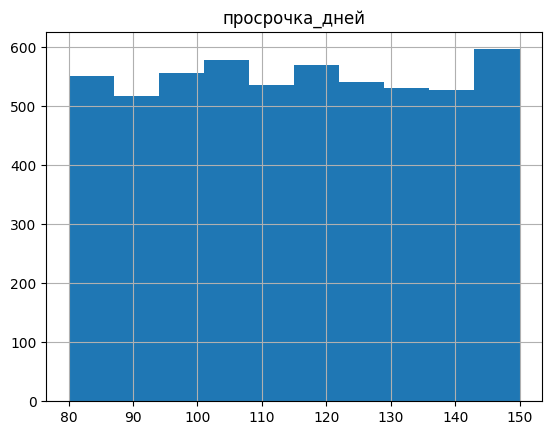

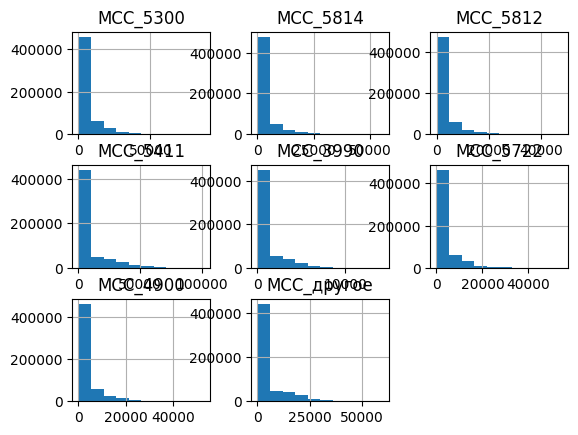

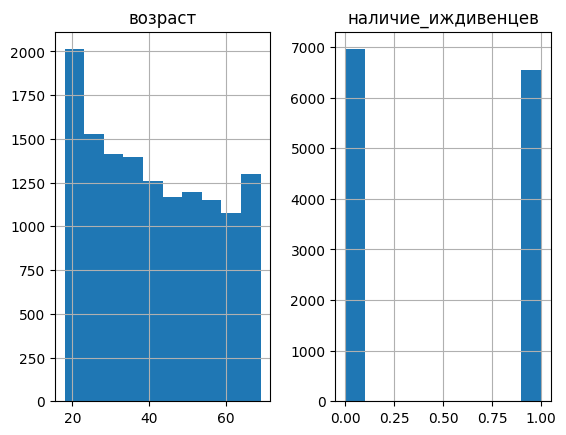

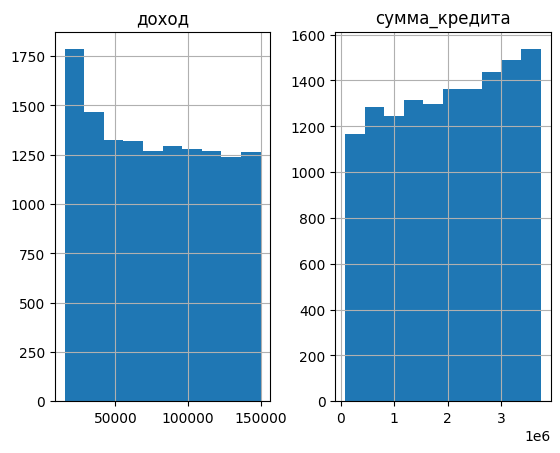

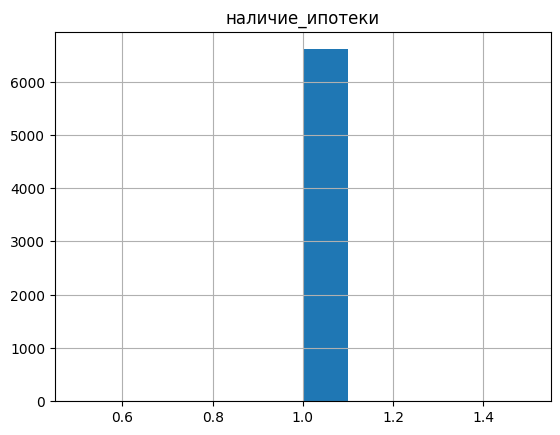

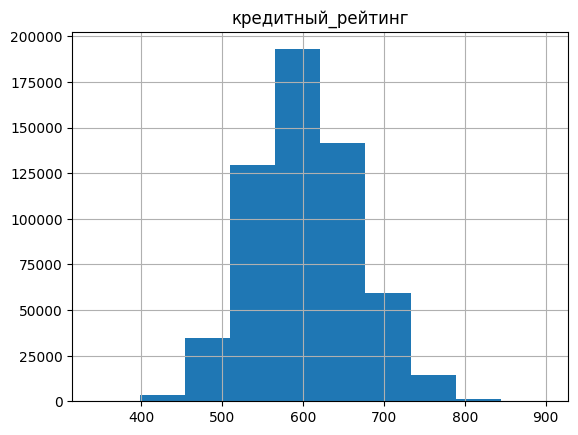

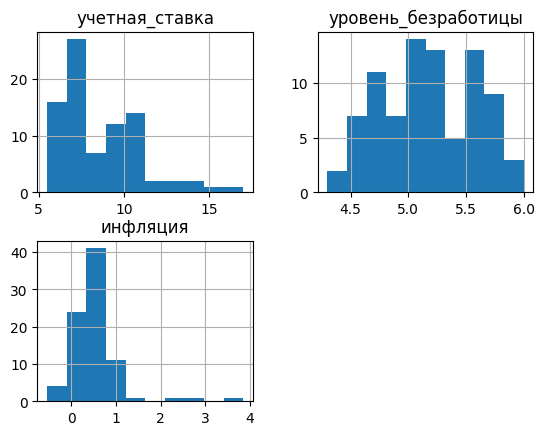

In [5]:
for name, df in tables.items():
    print('='*30)
    print(f'АНАЛИЗ ТАБЛИЦЫ {name}')
    print()
    start_analyze(df)
    print()

По результатам предварительного анализа можно сделать следующие выводы:
-  load_payment_credit:
	- пропусков и дубликатов нет;
	- надо будет привести столбец "дата_начала_периода" к типу date и, возможно, поменять название;
	-  в столбце "просрочка_дней" значения равномерно распределены
-  transactions: 
	- пропусков и дубликатов нет;
	- надо будет привести столбец "date" к типу date;
	- все столбцы "MCC" имеют явный правый хвост;
- client_description:
	- пропусков и дубликатов нет;
	- "дата_регистрации", если будем ее использовать, надо будет привести к типу date
	-  в столбце "возраст" преобладают молодые, иждевенцы  
- credit_description
	- пропусков и дубликатов нет;
	- "Доход" и "сумма кредита" распределены плюс минус равномерно, хотя прослеживается, что низкого дохода меньше, чем высокого, а сумма кредита - наоборот
- mortgage_presence
	- пропусков и дубликатов нет;
	- у всех клиентов есть ипотека;
- credit_rating
	- пропусков и дубликатов нет;
	- надо будет привести столбец "date" к типу date;
	- кредитный рейтинг показывает идеальное нормальное распределение
- macro_data
	- пропусков и дубликатов нет;
	- учетная ставка скачет,
	- уровень безработицы распределен почти нормально, но в районе 5,5 наблюдается снижение
	- инфляция находится в районе 0-1, но с правым хвостом
- cohort_grid
	- пропусков и дубликатов нет;
	- надо будет привести столбец "score_date" к типу date;


Преобразуем Дату в тип Date

In [6]:
load_payment_credit['дата_начала_периода'] = pd.to_datetime(load_payment_credit['дата_начала_периода'])
transactions['date'] = pd.to_datetime(transactions['date'])
client_description['дата_регистрации'] = pd.to_datetime(client_description['дата_регистрации'])
mortgage_presence['дата_открытия'] = pd.to_datetime(mortgage_presence['дата_открытия'])
credit_rating['date'] = pd.to_datetime(credit_rating['date'])
macro_data['date'] = pd.to_datetime(macro_data['date'])
cohort_grid['score_date'] = pd.to_datetime(cohort_grid['score_date'])

## Объединение таблиц

Соберите все источники данных о клиентах в единую таблицу наблюдений.

### Формирование целевой переменной

1. Значение бинарной целевой переменной нужно определить для каждой строки со столбцами `ID` и `score_date` в таблице `cohort_grid`.

2. Таргет равен 1 при соблюдении двух условий:
    * Если значение в поле `просрочка_дней` больше или равно 90.
    * Если для клиента существует строка в таблице `loan_payment_credit`, где значение в поле `дата_начала_периода` попадает в интервал `[score_date, score_date + 365 дней)`.

>Важно: у клиента может быть несколько эпизодов с просрочками от 90 дней. Вам нужно взять первый по времени возникновения эпизод в таблице с просрочками.

3. После расчёта целевой переменной удалите строки, где дефолт уже произошёл к моменту скоринга, то есть `дата_начала_периода < score_date`. Это необходимо, так как для корректной работы с временной структурой важно учитывать дефолты, произошедшие в прошлом относительно даты скоринга.

### Создание итоговой таблицы

1. В качестве признаков можно использовать только информацию о прошлом, то есть она должна быть доступна к дате скоринга. Иными словами, в каждой строке нужно присоединить данные о поведении клиента за предыдущие периоды относительно даты скоринга, иначе произойдёт утечка данных из будущего.

>К примеру, `score_date = 2024-01-15`. Тогда:
>* транзакции за декабрь 2023 г. — можем использовать;
>* транзакции за ноябрь 2023 г. — можем использовать;
>* транзакции 16 января 2024 г. — **не** можем использовать.

2. Присоедините остальные данные по клиенту, помимо указанных выше данных о макроэкономике и транзакциях клиента.

> Рекомендации:
>* Не забывайте проверять правильность каждого этапа сбора данных в единую таблицу. Это можно отслеживать на одном из клиентов.
>* При формировании таблицы следите за тем, чтобы в ней была корректно проведена работа со временем:
  >   * Отследите, не упущены ли какие-то данные из прошлого;
  >   * Проконтролируйте, верно ли рассчитана целевая переменная, которая зависит от дефолта в будущем.
>* Помните, что даты в исходных таблицах указаны на первое число месяца. Учитывайте период, который они описывают.

Сделайте выводы о получившейся таблице.

Для начала проверим еще раз таблицу cohort_grid

In [7]:
print('Размер:', cohort_grid.shape)
print('Уникальных клиентов:', cohort_grid['ID'].nunique())

print(
    'Дубликатов ID + score_date:',
    cohort_grid.duplicated(['ID', 'score_date']).sum()
)

print('Первая дата:', cohort_grid['score_date'].min())
print('Последняя дата:', cohort_grid['score_date'].max())

Размер: (577494, 2)
Уникальных клиентов: 13500
Дубликатов ID + score_date: 0
Первая дата: 2013-01-01 00:00:00
Последняя дата: 2019-12-01 00:00:00


Попробуем предворительно соединить таблицы transactions и credit_rating с cohort_grid, посмотреть как они будут объединяться.

In [8]:
transactions_keys = (
    transactions[['ID', 'date']]
    .rename(columns={'date': 'score_date'})
)

check_transactions = cohort_grid[['ID', 'score_date']].merge(
    transactions_keys,
    on=['ID', 'score_date'],
    how='outer',
    indicator=True
)

print(check_transactions['_merge'].value_counts())

_merge
both          577494
left_only          0
right_only         0
Name: count, dtype: int64


In [9]:
credit_rating_keys = (
    credit_rating[['ID', 'date']]
    .rename(columns={'date': 'score_date'})
)

check_credit_rating = cohort_grid[['ID', 'score_date']].merge(
    credit_rating_keys,
    on=['ID', 'score_date'],
    how='outer',
    indicator=True
)

print(check_credit_rating['_merge'].value_counts())

_merge
both          577494
left_only          0
right_only         0
Name: count, dtype: int64


Пары значений ID и data уникальны. Теперь посмотрим дату открытия ипотеки относительно даты скоринга

In [10]:

mortgage_check = cohort_grid.merge(
    mortgage_presence,
    on='ID',
    how='left',
    indicator=True
)

print(mortgage_check['_merge'].value_counts())


_merge
left_only     296761
both          280733
right_only         0
Name: count, dtype: int64


Узнаем, есть ли случаи, когда взяли ипотеку до скоринга

In [11]:
print('Дата открытия отсутствует:')
print(mortgage_check['дата_открытия'].isna().sum())

print('\nДата открытия позже даты скоринга:')
print(
    (
        mortgage_check['дата_открытия'].notna()
        & (mortgage_check['дата_открытия'] > mortgage_check['score_date'])
    ).sum()
)

Дата открытия отсутствует:
296761

Дата открытия позже даты скоринга:
0


Таких ситуаций нет, но есть клиенты, которые не брали ипотеку

In [12]:
final_df = cohort_grid.merge(
    load_payment_credit,
    on=['ID'],
    how='left')
final_df = final_df.merge(
    transactions,
    left_on=['ID', 'score_date'],
    right_on=['ID', 'date'],
    how='left')
final_df = final_df.merge(
    client_description,
    on=['ID'],
    how='left')
final_df = final_df.merge(
    credit_description,
    on=['ID'],
    how='left')
final_df = final_df.merge(
    mortgage_presence,
    on=['ID'],
    how='left')
final_df = final_df.merge(
    credit_rating,
    left_on=['ID', 'score_date'],
    right_on=['ID', 'date'],
    how='left')
final_df = final_df.merge(
    macro_data,
    left_on=['score_date'],
    right_on=['date'],
    how='left')



Проверим как объединилась таблица

In [13]:
final_df.head()

,ID,score_date,дата_начала_периода,просрочка_дней,date_x,MCC_5300,MCC_5814,MCC_5812,MCC_5411,MCC_3990,...,доход,сумма_кредита,дата_открытия,наличие_ипотеки,date_y,кредитный_рейтинг,date,учетная_ставка,уровень_безработицы,инфляция
0,IDF55109846,2013-05-01,2014-12-01,120.0,2013-05-01,3267.59,1282.11,1457.96,5711.10,647.43,...,27035,1960785,NaT,NaN,2013-05-01,692,2013-05-01,5.5,5.4,0.66
1,IDF55109846,2013-06-01,2014-12-01,120.0,2013-06-01,3196.58,2443.37,1334.20,5824.65,1067.55,...,27035,1960785,NaT,NaN,2013-06-01,688,2013-06-01,5.5,5.3,0.42
2,IDF55109846,2013-07-01,2014-12-01,120.0,2013-07-01,3550.54,4277.72,1463.75,5209.51,1167.95,...,27035,1960785,NaT,NaN,2013-07-01,666,2013-07-01,5.5,5.3,0.82
3,IDF55109846,2013-08-01,2014-12-01,120.0,2013-08-01,3385.98,4530.63,1261.40,5765.96,986.99,...,27035,1960785,NaT,NaN,2013-08-01,692,2013-08-01,5.5,5.2,0.14
4,IDF55109846,2013-09-01,2014-12-01,120.0,2013-09-01,3214.84,4146.65,1405.15,5632.11,640.76,...,27035,1960785,NaT,NaN,2013-09-01,688,2013-09-01,5.5,5.1,0.21


In [14]:
final_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 577494 entries, 0 to 577493
Data columns (total 27 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   ID                   577494 non-null  object        
 1   score_date           577494 non-null  datetime64[ns]
 2   дата_начала_периода  234907 non-null  datetime64[ns]
 3   просрочка_дней       234907 non-null  float64       
 4   date_x               577494 non-null  datetime64[ns]
 5   MCC_5300             577494 non-null  float64       
 6   MCC_5814             577494 non-null  float64       
 7   MCC_5812             577494 non-null  float64       
 8   MCC_5411             577494 non-null  float64       
 9   MCC_3990             577494 non-null  float64       
 10  MCC_5722             577494 non-null  float64       
 11  MCC_4900             577494 non-null  float64       
 12  MCC_другое           577494 non-null  float64       
 13  возраст       

In [15]:
final_df['test'] = (final_df['date'] == final_df['date_x']) & (final_df['date'] == final_df['date_y']) & (final_df['score_date'] == final_df['date_y'])
sum(final_df['test'] == False)

0

Все даты одинаковы, можно удалить столбцы data, data_x, data_y. 

Создадим столбец target

In [16]:
final_df['target'] =(
    (final_df['просрочка_дней'] >= 90)
    &((final_df['дата_начала_периода'] + pd.DateOffset(days=90)).dt.to_period('M') > final_df['score_date'].dt.to_period('M')) 
    &((final_df['дата_начала_периода'] + pd.DateOffset(days=90)).dt.to_period('M') <= (final_df['score_date'] + pd.DateOffset(months=12)).dt.to_period('M'))
).astype('int')

In [17]:
final_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 577494 entries, 0 to 577493
Data columns (total 29 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   ID                   577494 non-null  object        
 1   score_date           577494 non-null  datetime64[ns]
 2   дата_начала_периода  234907 non-null  datetime64[ns]
 3   просрочка_дней       234907 non-null  float64       
 4   date_x               577494 non-null  datetime64[ns]
 5   MCC_5300             577494 non-null  float64       
 6   MCC_5814             577494 non-null  float64       
 7   MCC_5812             577494 non-null  float64       
 8   MCC_5411             577494 non-null  float64       
 9   MCC_3990             577494 non-null  float64       
 10  MCC_5722             577494 non-null  float64       
 11  MCC_4900             577494 non-null  float64       
 12  MCC_другое           577494 non-null  float64       
 13  возраст       

Обработаем таблицу. Переработаем столбец с наличием ипотеки, удалим ненужные столбцы. ID пока оставим в таблице, но как признак использовать его не будем.

In [18]:
final_df['наличие_ипотеки'] = (
    final_df['дата_открытия'].notna()
    & (final_df['дата_открытия'] <= final_df['score_date'])
).astype('int')

In [19]:
cols_to_drop = [
    'date_x',
    'date_y',
    'date',
    'дата_начала_периода',
    'просрочка_дней',
    'дата_открытия',
    'test'
]

final_df = final_df.drop(columns=cols_to_drop)

In [20]:
final_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 577494 entries, 0 to 577493
Data columns (total 22 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   ID                   577494 non-null  object        
 1   score_date           577494 non-null  datetime64[ns]
 2   MCC_5300             577494 non-null  float64       
 3   MCC_5814             577494 non-null  float64       
 4   MCC_5812             577494 non-null  float64       
 5   MCC_5411             577494 non-null  float64       
 6   MCC_3990             577494 non-null  float64       
 7   MCC_5722             577494 non-null  float64       
 8   MCC_4900             577494 non-null  float64       
 9   MCC_другое           577494 non-null  float64       
 10  возраст              577494 non-null  int64         
 11  семейное_положение   577494 non-null  object        
 12  наличие_иждивенцев   577494 non-null  int64         
 13  дата_регистрац

In [21]:
final_df['семейное_положение'].unique()

array(['разведённые', 'нет семьи', 'есть семья'], dtype=object)

В дальнейшем надо будет обработать с помощью OneHotEncoder

## Создание новых признаков

* Добавьте в таблицу новые признаки, которые помогли бы описать поведение клиента. Создайте не менее двух новых признаков.
* Сделайте выводы о новых признаках.

In [22]:
final_df_new = final_df.sort_values(
    ['ID', 'score_date']
).copy()

final_df_new['MCC_total'] = final_df_new['MCC_5300'] + final_df_new['MCC_5814'] + final_df_new['MCC_5812'] + final_df_new['MCC_5411'] + final_df_new['MCC_3990'] + final_df_new['MCC_5722'] + final_df_new['MCC_4900'] + final_df_new['MCC_другое']

final_df_new['MCC_3_month_mean'] = (
    final_df_new.groupby('ID')['MCC_total']
    .transform(
        lambda s: s.shift(1)
        .rolling(window=3, min_periods=1)
        .mean()
    )
)


Создали 2 новых признака - `MCC_total` - общая сумма трат пользователя за месяц; `MCC_3_month_mean` - скользящее окно, которое показывает среднюю сумму трат пользователя за 3 месяца.

In [23]:
final_df_new[['MCC_total', 'MCC_3_month_mean']].describe()

,MCC_total,MCC_3_month_mean
count,577494.000000,563994.000000
mean,35771.705692,37679.655680
std,46744.238127,45541.959306
min,1190.350000,1432.183333
25%,8391.992500,9260.516667
50%,16023.570000,17428.821667
75%,34938.170000,47054.064167
max,309029.080000,261654.790000


<Axes: >

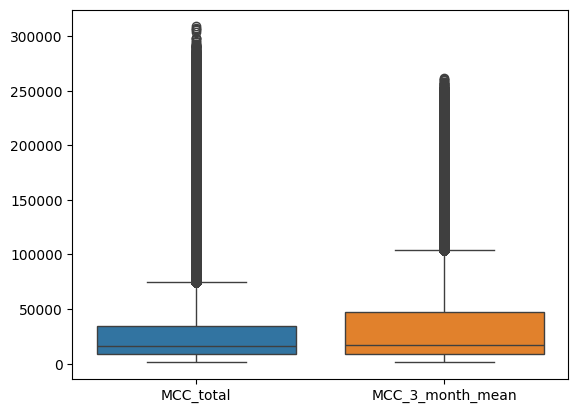

In [24]:
sns.boxplot(data=final_df_new[['MCC_total', 'MCC_3_month_mean']])

<Axes: ylabel='Count'>

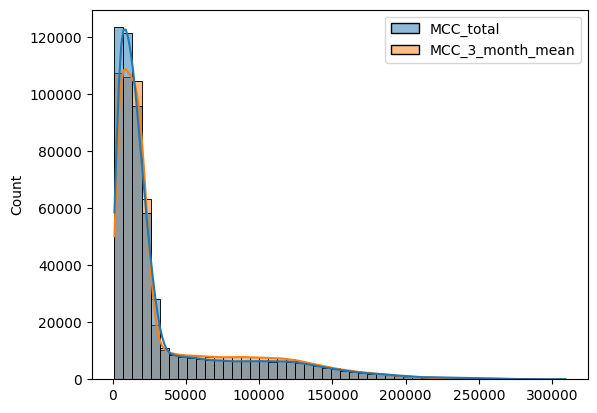

In [25]:
sns.histplot(data=final_df_new[['MCC_total', 'MCC_3_month_mean']], bins=50, kde=True)

По цифрам признак выглядит вполне правдоподобно. Видно, что скользящее среднее сглаживает колебания. Cтандартное отклонение и максимум уменьшились. Cреднее и медиана скользящего среднего выше. Пропуски встречаются из-за того, что нет "истории", заменим их потом медианным значением.

## Анализ итоговой таблицы

* Проведите краткий анализ получившейся итоговой таблицы.
* Сделайте вывод о данных для моделирования.
* Проверьте целевую переменную на предмет дисбаланса классов. Сделайте выводы.

In [ ]:

profile = ProfileReport(
    final_df_new,
    explorative=True)

profile.to_notebook_iframe()

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 24/24 [00:09<00:00,  2.51it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

## Моделирование

### Базовые модели

1. Подготовьте обучающую, калибровочную и тестовую выборки. Разбейте обучающую на три фолда для последующего использования кросс-валидации. Для оценки качества и калибровки используйте размер выборки, равный 12 месяцам.


2. При необходимости проведите категоризацию данных, применив нужный Encoder и использовав пайплайн.

3. Обучите базовые модели с кросс-валидацией по трём фолдам:
    * Две базовые модели — логистическую регрессию и случайный лес — без балансировки классов в целевой переменной.
    * Логистическую регрессию и случайный лес с балансировкой классов. Выберите метод балансировки самостоятельно. Обязательно примените хотя бы один метод. Можно попробовать несколько и выбрать лучший.
    * Сделайте выводы о работе всех четырёх моделей.

4. Случайный лес с настройками по умолчанию легко переобучается, потому что запоминает обучающую выборку, из-за чего модель может терять в качестве на новых данных. Логистическая регрессия же сразу готова к работе за счёт встроенной L2-регуляризации, которая автоматически контролирует сложность модели.

   Чтобы исправить проблемы модели Random Forest, вам нужно подобрать для неё гиперпараметры с помощью  Optuna. Количество гиперпараметров должно быть не менее трёх. Для оптимизации используйте метрику missed defaults rate.

5. Сравните все полученные модели.

6. Для оценки моделей используйте метрики:
   * accuracy или ROC-AUC,
   * approval rate,
   * default rate,
   * missed defaults rate.

7. Сделайте вывод о работе, проделанной в этом разделе.

## Калибровка модели и пересчёт результатов

* Проведите калибровку лучшей версии модели. Используйте отдельную калибровочную выборку.
* Используйте метод, подходящий для случайного леса.
* Постройте график калибровки.
* Сделайте вывод, оцените результаты с помощью коэффициента Бриера.

## Поиск порога решения

* Используя откалиброванную модель и калибровочную выборку, найдите порог, при котором будут достигнуты заданные в постановке задачи значения метрик:
    * approval rate — не менее 65%;
    * default rate — не более 2%;
    * missed defaults rate — не более 4%.
    
* Сделайте вывод о достигнутых в этом разделе результатах.

## Анализ матрицы ошибок

* Оцените стабильность модели на тестовых данных. Для этого постройте:
    * матрицу ошибок на калибровочных данных;
    * матрицу классификации на тестовых данных.
* Сделайте вывод о моделях, рассчитав классические метрики машинного обучения и указанные в ТЗ бизнес-метрики.
* Сделайте вывод о стабильности модели.

## Фиксирование итоговой модели

- Опишите лучшую модель и найденный порог классификации.


## Анализ важности признаков

* Проведите анализ важности признаков найденной модели на полных тренировочных данных.
* Используйте `feature_importances_` для найденной модели.
* Сделайте вывод о силе влияния признаков на дефолт.

## Выводы по проекту

Сделайте выводы по проекту. Можете использовать такой план:

1. Цель и задачи исследования.

2. Подготовка данных и выборок.

3. Поиск и настройка модели.

4. Калибровка вероятностей.

5. Оптимизация бизнес-порога.

6. Анализ важности признаков.

7. Финальный пайплайн.

8. Основные выводы и рекомендации для бизнеса.

